In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

## Commute Flows

In [ ]:
data = r"/home/cank/agent-folder/thrive-commute/data/processed/flows_home_in_region_2023_pts.csv"
data = pd.read_csv( data )
data.head()

,home_tract,home_lat,home_lon,work_tract,work_lat,work_lon,jobs
0,47143975401,35.493881,-85.021068,47143975401,35.493881,-85.021068,1094.0
1,47143975200,35.557499,-84.960235,47143975401,35.493881,-85.021068,872.0
2,47143975300,35.496202,-85.067522,47143975401,35.493881,-85.021068,656.0
3,13111050200,34.949548,-84.352854,13111050400,34.862943,-84.331657,654.0
4,13313001200,34.729015,-84.932562,13313001200,34.729015,-84.932562,648.0


In [18]:
data['jobs_perc'] = data['jobs'] * 100 / data['jobs'].sum(axis=0)
data.sort_values(by='jobs_perc', ascending=False).head()

,home_tract,home_lat,home_lon,work_tract,work_lat,work_lon,jobs,jobs_perc
0,47143975401,35.493881,-85.021068,47143975401,35.493881,-85.021068,1094.0,0.209830
1,47143975200,35.557499,-84.960235,47143975401,35.493881,-85.021068,872.0,0.167250
2,47143975300,35.496202,-85.067522,47143975401,35.493881,-85.021068,656.0,0.125821
3,13111050200,34.949548,-84.352854,13111050400,34.862943,-84.331657,654.0,0.125438
4,13313001200,34.729015,-84.932562,13313001200,34.729015,-84.932562,648.0,0.124287


In [36]:
data['jobs'].quantile(0.05)
data_filtered = data[ data['jobs'] > 1 ].copy()


In [37]:
from shapely.geometry import LineString

data_filtered['geometry'] = data_filtered.apply( lambda x:  LineString([(x['home_lon'], x['home_lat']), (x['work_lon'], x['work_lat'])]) , axis=1 )
gdf = gpd.GeoDataFrame( data_filtered , geometry='geometry' , crs=4326 )
data_filtered.head()

,home_tract,home_lat,home_lon,work_tract,work_lat,work_lon,jobs,jobs_perc,geometry
0,47143975401,35.493881,-85.021068,47143975401,35.493881,-85.021068,1094.0,0.209830,"LINESTRING (-85.0210675 35.4938808, -85.021067..."
1,47143975200,35.557499,-84.960235,47143975401,35.493881,-85.021068,872.0,0.167250,"LINESTRING (-84.960235 35.5574995, -85.0210675..."
2,47143975300,35.496202,-85.067522,47143975401,35.493881,-85.021068,656.0,0.125821,"LINESTRING (-85.0675217 35.4962018, -85.021067..."
3,13111050200,34.949548,-84.352854,13111050400,34.862943,-84.331657,654.0,0.125438,"LINESTRING (-84.3528536 34.9495478, -84.331656..."
4,13313001200,34.729015,-84.932562,13313001200,34.729015,-84.932562,648.0,0.124287,"LINESTRING (-84.9325622 34.729015, -84.9325622..."


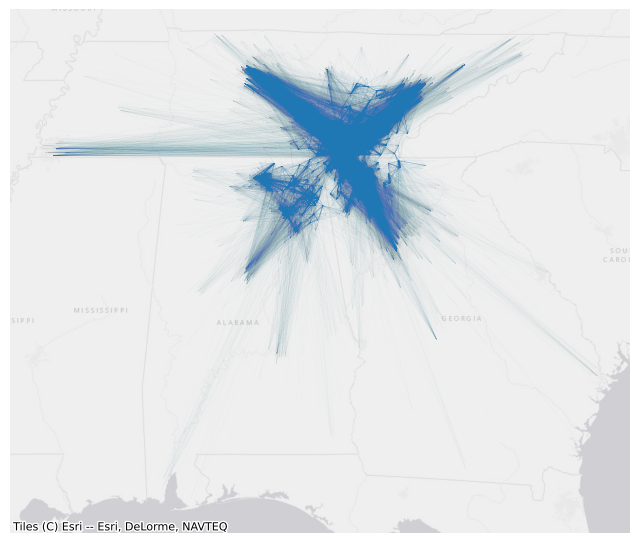

In [38]:
import contextily as ctx
fig,ax = plt.subplots( figsize=(8,8))
gdf.to_crs(3857).plot( ax=ax , linewidth= gdf['jobs_perc']*10)
ax.axis('off')
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)

In [40]:
gdf.to_file( r"/home/cank/agent-folder/thrive-commute/data/processed/flow_inregion.geojson" , driver="GeoJSON" )

## CFS - Freight Flows

In [2]:
import duckdb
cfs_path = r"/mnt/c/Users/cansu/Downloads/cfs_2022_pums/cfs_2022_pums.csv"
cfs = duckdb.sql( f"SELECT * FROM '{cfs_path}' WHERE ORIG_STATE IN ('01','13','47') OR DEST_STATE IN ('01','13','47')").to_df()
cfs.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,SHIPMT_ID,ORIG_STATE,ORIG_MA,ORIG_CFS_AREA,DEST_STATE,DEST_MA,DEST_CFS_AREA,SECTOR,SCTG,MODE,SHIPMT_VALUE,SHIPMT_WGHT,SHIPMT_DIST_GC,TEMP_CNTL_YN,EXPORT_YN,EXPORT_CNTRY,HAZMAT,WGT_FACTOR
0,00000003,13,122,13-122,06,348,06-348,31-33,29,112,433,213,1945,N,N,N,N,62.7
1,00000010,47,400,47-400,48,206,48-206,31-33,39,21,16,3,612,N,N,N,N,128.5
2,00000018,01,99999,01-99999,48,288,48-288,48-49,30,111,93,9,578,N,N,N,N,30.9
3,00000030,17,99999,17-99999,13,496,13-496,48-49,36,111,7616,1060,751,N,Y,A,N,32.8
4,00000036,13,122,13-122,13,122,13-122,42,27,112,438,393,28,N,N,N,N,86.1


In [3]:
cfs.sort_values(['ORIG_CFS_AREA','DEST_CFS_AREA']).head()
cfs_simpler = cfs.groupby(['ORIG_CFS_AREA','DEST_CFS_AREA']).agg({
    'SHIPMT_VALUE': 'sum', 
    'SHIPMT_WGHT': 'sum'
}).reset_index()

cfs_simpler.head()

,ORIG_CFS_AREA,DEST_CFS_AREA,SHIPMT_VALUE,SHIPMT_WGHT
0,00-00000,01-380,74478,40584
1,00-00000,01-99999,13324766,48085059
2,00-00000,13-122,338,249
3,00-00000,13-496,29,51
4,00-00000,13-99999,3634,1186


In [4]:
cfs_simpler.to_csv("/home/cank/agent-folder/thrive-commute/data/processed/cfs_simpler.csv" )

In [17]:
cfs_2 = pd.read_csv( "/home/cank/agent-folder/thrive-commute/data/processed/cfs_area_flows_pts.csv")
cfs_2 = cfs_2.dropna( how='any' )


from shapely.geometry import LineString
cfs_2['geometry'] = cfs_2.apply( lambda x:  LineString([(x['orig_lon'], x['orig_lat']), (x['dest_lon'], x['dest_lat'])]) , axis=1 )
cfs_2 = gpd.GeoDataFrame( cfs_2 , geometry='geometry' , crs=4326 )
# cfs_2 = cfs_2.drop( columns = ['orig_lat','orig_lon','dest_lat','dest_lon'] )
cfs_2.head()

,ORIG_CFS_AREA,orig_name,orig_lat,orig_lon,DEST_CFS_AREA,dest_name,dest_lat,dest_lon,SHIPMT_VALUE,SHIPMT_WGHT,geometry
9,01-142,"Birmingham-Hoover-Talladega, AL CFS Area",33.977357,-86.56644,01-142,"Birmingham-Hoover-Talladega, AL CFS Area",33.977357,-86.566440,158411922,444589910,"LINESTRING (-86.56644 33.97736, -86.56644 33.9..."
10,01-142,"Birmingham-Hoover-Talladega, AL CFS Area",33.977357,-86.56644,01-380,"Mobile-Daphne-Fairhope, AL CFS Area",30.684573,-88.196568,35612930,233702874,"LINESTRING (-86.56644 33.97736, -88.19657 30.6..."
11,01-142,"Birmingham-Hoover-Talladega, AL CFS Area",33.977357,-86.56644,01-99999,Remainder of Alabama,33.270400,-85.863525,110515294,117076617,"LINESTRING (-86.56644 33.97736, -85.86353 33.2..."
12,01-142,"Birmingham-Hoover-Talladega, AL CFS Area",33.977357,-86.56644,02-99999,Remainder of Alaska,55.449938,-131.106685,46460,11909,"LINESTRING (-86.56644 33.97736, -131.10668 55...."
13,01-142,"Birmingham-Hoover-Talladega, AL CFS Area",33.977357,-86.56644,04-429,"Phoenix-Mesa, AZ CFS Area",32.918521,-111.366339,568808,302381,"LINESTRING (-86.56644 33.97736, -111.36634 32...."


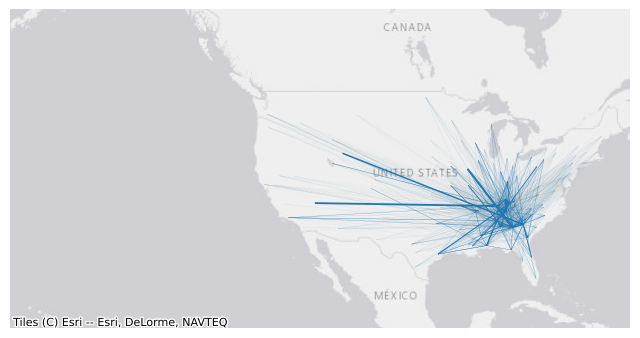

In [18]:
import contextily as ctx
fig,ax = plt.subplots( figsize=(8,8))
cfs_2.to_crs(3857).plot( ax=ax , linewidth= cfs_2['SHIPMT_WGHT']/300000000)
ax.axis('off')
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)

<Axes: >

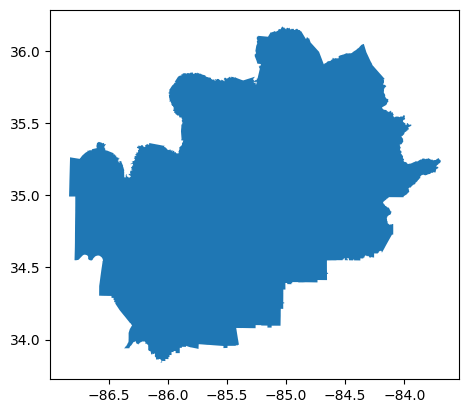

In [19]:
boundary = "/mnt/c/Users/cansu/Dropbox/studio2263/Thrive/GIS/base_map/thrive_boundaries/thrive_secondary_boundary.geojson"
boundary = gpd.read_file( boundary )
boundary = boundary.to_crs(4326)
boundary.plot()

<Axes: >

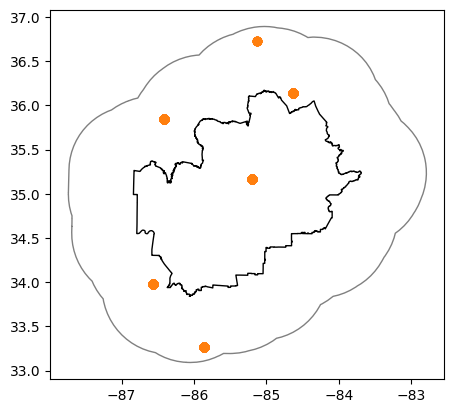

In [52]:
cfs_2_origin = gpd.GeoDataFrame( cfs_2 , geometry=gpd.points_from_xy(cfs_2['orig_lon'], cfs_2['orig_lat'] ), crs=4326 )
cfs_2_dest = gpd.GeoDataFrame( cfs_2 , geometry=gpd.points_from_xy(cfs_2['dest_lon'], cfs_2['dest_lat'] ), crs=4326 )

buffered_bounds = boundary.set_geometry( boundary.to_crs(3857).buffer(100000) ).to_crs(4326)

cfs_2_origin = gpd.sjoin(cfs_2_origin, buffered_bounds, predicate='within' )
cfs_2_dest = gpd.sjoin(cfs_2_dest, buffered_bounds, predicate='within' )

fig,ax = plt.subplots()

cfs_2_origin.plot( ax=ax , markersize=3)
cfs_2_dest.plot( ax=ax )
boundary.plot( ax=ax, fc='none' )
buffered_bounds.plot( ax=ax, ec='grey', fc='none')


(np.float64(-162.60170096500002),
 np.float64(-65.807707735),
 np.float64(19.507205730000003),
 np.float64(57.16149647))

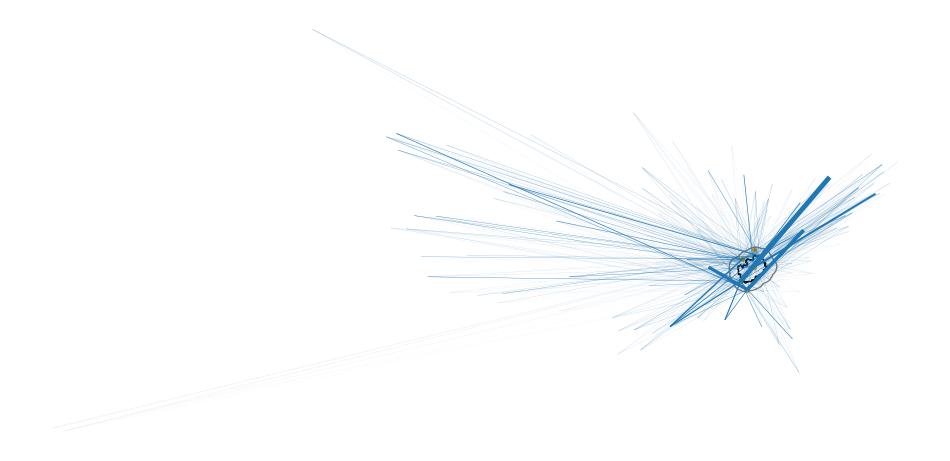

In [69]:

cfs_2_chat = cfs_2[
    cfs_2['ORIG_CFS_AREA'].isin( cfs_2_origin['ORIG_CFS_AREA'].unique() ) | 
    cfs_2['DEST_CFS_AREA'].isin( cfs_2_dest['DEST_CFS_AREA'].unique() )
]


fig,ax = plt.subplots( figsize=(12,12) )

cfs_2_chat.plot( ax=ax , linewidth= cfs_2['SHIPMT_WGHT']/300000000 )
cfs_2_origin.plot( ax=ax , markersize=4, color='orange')

boundary.plot( ax=ax, fc='none' )
buffered_bounds.plot( ax=ax, ec='grey', fc='none')
ax.axis('off')

In [73]:
cfs_2_chat.to_file( "~/agent-folder/thrive-commute/data/processed/cfs_chattanooga.geojson", driver="GeoJSON" )